---

# Tugas Besar 2 IF3170 Inteligensi Artifisial

*This notebook is the assignment template. Each group works on its own copy, and cells or sections may be added as needed.*

---

## Group 28

- Varistha Devi (1524135)
- Mirza Tsabita Wafa'ana (13524114)
- Eliana Natalie Widjojo (13524116)
- A. Rinofaros (13524138)
- Safira Berlianti (13524128)

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Understanding (Optional)**](#3)
4. [**Training and Validation Split**](#4)
5. [**Data Preparation**](#5)
6. [**Preparation Pipeline**](#6)
7. [**Modeling and Validation**](#7)
8. [**Comparison with scikit-learn**](#8)
9. [**Saving and Loading Models**](#9)
10. [**Kaggle Submission**](#10)
11. [**Error Analysis**](#11)


---

# Introduction <a name="1"></a>

---

This section frames the problem in the words of the group.

## Overview

*To be written by the group.*

## Aim

*To be written by the group.*

## Metric

*To be written by the group.*

## Dataset

*To be written by the group.*

## Approach

*To be written by the group.*

---

# Initialization <a name="2"></a>

---

This section prepares the environment, the settings, and the data files.

## Environment Setup

The following cell lists the base libraries. The install line is commented by default.

In [15]:
# %pip install -q numpy pandas

## Import Libraries

Every import of the notebook is kept in this cell.

In [58]:
import os
import sys
import subprocess
import importlib
import random
from pathlib import Path

REPO_NAME = "IF3170_G28_HaalinghamJayaAO3"
REPO_URL = f"https://github.com/EliWidjojo/{REPO_NAME}.git"

# Cari root repo dari folder kerja notebook dan semua folder induknya.
repo_root = None
cwd = Path.cwd().resolve()
for candidate in (cwd, *cwd.parents):
    if (candidate / "src").is_dir() and (candidate / "data").is_dir():
        repo_root = candidate
        break

# Jika notebook dijalankan di Google Colab dan repo belum tersedia, clone repository ke /content/<nama-repo>.
if repo_root is None and Path("/content").is_dir():
    colab_repo = Path("/content") / REPO_NAME
    if not (colab_repo / "src").is_dir():
        subprocess.run(["git", "clone", REPO_URL, str(colab_repo)], check=True)
    if (colab_repo / "src").is_dir():
        repo_root = colab_repo.resolve()

if repo_root is None:
    raise FileNotFoundError(
        "Root repository tidak ditemukan. Jalankan notebook dari folder repo "
        "atau pastikan folder src/ dan data/ tersedia."
    )

os.chdir(repo_root)
repo_root_str = str(repo_root)
if repo_root_str not in sys.path:
    sys.path.insert(0, repo_root_str)
importlib.invalidate_caches()

# Hapus cache modul src agar perubahan knn.py/log_reg.py/nb.py terbaru benar-benar dimuat.
for module_name in list(sys.modules):
    if module_name == "src" or module_name.startswith("src."):
        del sys.modules[module_name]
importlib.invalidate_caches()

print(f"Repository root: {repo_root}")


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, OneHotEncoder, KBinsDiscretizer, OrdinalEncoder
from sklearn.decomposition import PCA
from sklearn.svm import SVC, LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import CategoricalNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix,
)

from src.knn.knn import KNN
from src.decision_tree.cart import DecisionTreeCART
from src.log_reg.log_reg import LogisticReg
from src.svm.svm import SVM
from src.naive_bayes.nb import NaiveBayes

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

Repository root: D:\Github Repos\IF3170_G28_HaalinghamJayaAO3


## Settings

Paths and shared constants are kept in this class.

In [17]:
class Settings:
    SEED = 42
    DATA_DIR = Path("data")
    OUTPUT_DIR = Path("output")
    TARGET = "is_canceled"
    VALIDATION_SIZE = 0.20
    OUTLIER_IQR_FACTOR = 1.5
    APPLY_PCA = False
    PCA_VARIANCE = 0.95
    APPLY_RANDOM_OVERSAMPLING = False

CFG = Settings()
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Seed Everything

A fixed seed keeps the results reproducible.

In [18]:
def seed_everything(seed: int):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

seed_everything(CFG.SEED)

## Load Dataset

The competition files are read here. The `id` column stays as text because some values resemble numbers.

In [19]:
train_path = CFG.DATA_DIR / "train.csv"
test_path = CFG.DATA_DIR / "test.csv"

if not train_path.exists():
    raise FileNotFoundError(
        f"File {train_path} tidak ditemukan. Letakkan train.csv di folder data/."
    )
if not test_path.exists():
    raise FileNotFoundError(
        f"File {test_path} tidak ditemukan. Letakkan test.csv di folder data/."
    )

train_df = pd.read_csv(train_path, dtype={"id": str})
test_df = pd.read_csv(test_path, dtype={"id": str})

print(f"Train: {train_df.shape}")
print(f"Test : {test_df.shape}")
display(train_df.head())

Train: (27373, 19)
Test : (6844, 18)


,id,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,room_category,days_before_arrival,arrival_year,arrival_month,arrival_day,booking_channel,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
0,57152f82,2.0,NaN,1,2,Breakfast,0.0,Type B,88.0,2024,4,3,Offline Agent,0,0,0,1330000.0,0.0,1
1,af2ec71b,2.0,0.0,2,1,Half Board,0.0,Type D,120.0,2023,8,1,Offline Agent,0,0,0,NaN,0.0,0
2,5d5469ab,3.0,0.0,1,2,Breakfast,0.0,Type G,209.0,2024,8,28,Online Travel Agent,0,0,0,2099000.0,0.0,1
3,d2df0369,2.0,1.0,2,1,Breakfast,0.0,Type G,93.0,2024,8,13,Online Travel Agent,0,0,0,1693000.0,2.0,0
4,91d253db,2.0,0.0,0,1,Room Only,0.0,Type B,14.0,2024,9,1,Online Travel Agent,0,0,0,2010000.0,2.0,0


---

# Data Understanding (Optional) <a name="3"></a>

---

Data understanding builds the knowledge that later preparation decisions rest on.

## Describe Data

This part covers the size, the attribute types, and the meaning of each column.

In [20]:
print("Ukuran dataset:", train_df.shape)
print("\nTipe data setiap atribut:")
display(pd.DataFrame({"dtype": train_df.dtypes, "n_unique": train_df.nunique(),}))

print("\nInformasi dataset:")
train_df.info()

print("\nStatistik deskriptif:")
display(train_df.describe(include="all").T)

Ukuran dataset: (27373, 19)

Tipe data setiap atribut:


,dtype,n_unique
id,str,27373
num_adults,float64,5
num_children,float64,6
weekend_nights,int64,8
weekday_nights,int64,18
meal_package,str,4
needs_parking,float64,2
room_category,str,7
days_before_arrival,float64,407
arrival_year,int64,2



Informasi dataset:
<class 'pandas.DataFrame'>
RangeIndex: 27373 entries, 0 to 27372
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id                        27373 non-null  str    
 1   num_adults                26564 non-null  float64
 2   num_children              24338 non-null  float64
 3   weekend_nights            27373 non-null  int64  
 4   weekday_nights            27373 non-null  int64  
 5   meal_package              25613 non-null  str    
 6   needs_parking             26291 non-null  float64
 7   room_category             26371 non-null  str    
 8   days_before_arrival       26250 non-null  float64
 9   arrival_year              27373 non-null  int64  
 10  arrival_month             27373 non-null  int64  
 11  arrival_day               27373 non-null  int64  
 12  booking_channel           27373 non-null  str    
 13  is_returning_guest        27373 non-null  int64  
 1

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,27373,27373,57152f82,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
num_adults,26564.0,NaN,NaN,NaN,1.845242,0.517974,0.0,2.0,2.0,2.0,4.0
num_children,24338.0,NaN,NaN,NaN,0.117388,0.425761,0.0,0.0,0.0,0.0,10.0
weekend_nights,27373.0,NaN,NaN,NaN,0.814854,0.875146,0.0,0.0,1.0,2.0,7.0
weekday_nights,27373.0,NaN,NaN,NaN,2.206517,1.421603,0.0,1.0,2.0,3.0,17.0
meal_package,25613,4,Breakfast,19654,NaN,NaN,NaN,NaN,NaN,NaN,NaN
needs_parking,26291.0,NaN,NaN,NaN,0.0302,0.171142,0.0,0.0,0.0,0.0,1.0
room_category,26371,7,Type B,20447,NaN,NaN,NaN,NaN,NaN,NaN,NaN
days_before_arrival,26250.0,NaN,NaN,NaN,85.379429,85.969638,0.0,17.0,58.0,126.0,448.0
arrival_year,27373.0,NaN,NaN,NaN,2023.820115,0.384099,2023.0,2024.0,2024.0,2024.0,2024.0


In [21]:
NUM_COLS = ["num_adults", "num_children", "weekend_nights", "weekday_nights", "days_before_arrival", "prior_cancellations", "prior_completed_bookings", "nightly_rate_idr", "special_requests"]
CAT_COLS = ["meal_package", "needs_parking", "room_category", "booking_channel", "is_returning_guest", "arrival_year", "arrival_month", "arrival_day"]

## Explore Data

This part covers distributions and relationships between attributes.

In [22]:
# Parameter grid dipakai di semua blok EDA di bawah
GRID_NCOLS = 3
N_NUM = len(NUM_COLS)
NROWS_NUM = (N_NUM + GRID_NCOLS - 1) // GRID_NCOLS
N_CAT = len(CAT_COLS)
NROWS_CAT = (N_CAT + GRID_NCOLS - 1) // GRID_NCOLS

### Distribusi Kelas Target

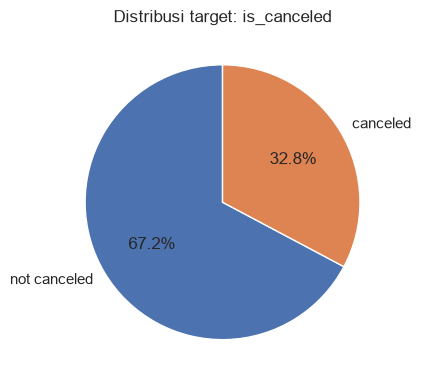

In [23]:
target_counts = train_df[CFG.TARGET].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(5, 4))
ax.pie(
    target_counts.values,
    labels=[f"not canceled" if c == 0 else "canceled" for c in target_counts.index],
    autopct="%.1f%%",
    colors=["#4C72B0", "#DD8452"],
    startangle=90,
)
ax.set_title("Distribusi target: is_canceled")
plt.tight_layout()
plt.show()

### Distribusi Fitur Numerik

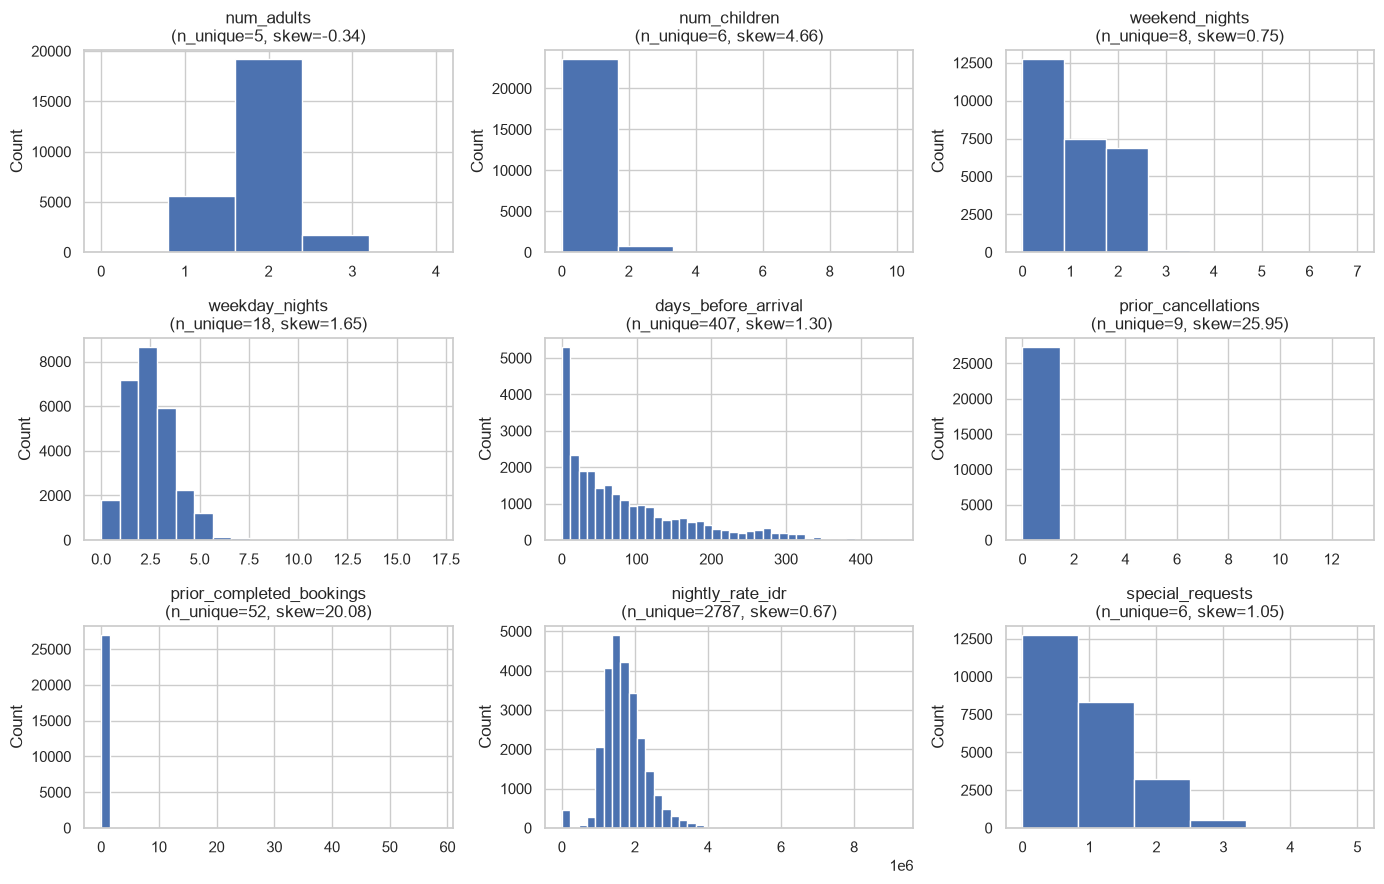

C:\Users\Infinix\AppData\Local\Temp\ipykernel_15292\4119627854.py:22: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[i].boxplot(train_df[col].dropna(), vert=True, patch_artist=True,
C:\Users\Infinix\AppData\Local\Temp\ipykernel_15292\4119627854.py:22: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[i].boxplot(train_df[col].dropna(), vert=True, patch_artist=True,
C:\Users\Infinix\AppData\Local\Temp\ipykernel_15292\4119627854.py:22: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[i].boxplot(train_df[col].dropna(), vert=True, patch_artist=True,
C:\Users\Infinix\AppData\Local\Temp\ipykernel_15292\4119627854.py:22: MatplotlibDeprecationWarning: ver

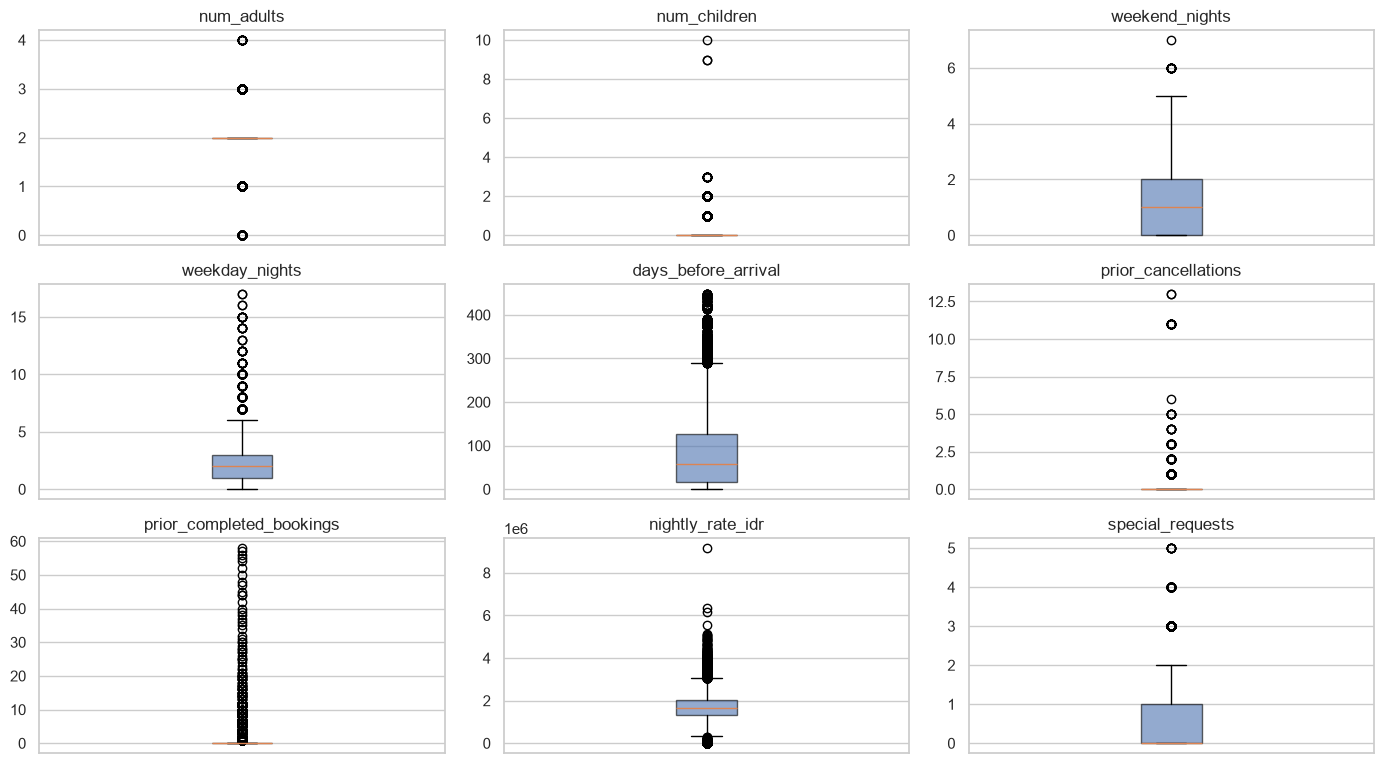

In [24]:
# histogram
fig, axes = plt.subplots(NROWS_NUM, GRID_NCOLS, figsize=(14, 3.0 * NROWS_NUM))
axes = axes.flatten()

for i, col in enumerate(NUM_COLS):
    bins = min(train_df[col].nunique(), 40)
    axes[i].hist(train_df[col].dropna(), bins=bins, color="#4C72B0", edgecolor="white")
    axes[i].set_title(f"{col}\n(n_unique={train_df[col].nunique()}, skew={train_df[col].skew():.2f})")
    axes[i].set_ylabel("Count")

for j in range(N_NUM, len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

# boxplot
fig, axes = plt.subplots(NROWS_NUM, GRID_NCOLS, figsize=(14, 2.6 * NROWS_NUM))
axes = axes.flatten()

for i, col in enumerate(NUM_COLS):
    axes[i].boxplot(train_df[col].dropna(), vert=True, patch_artist=True,
                    boxprops=dict(facecolor="#4C72B0", alpha=0.6))
    axes[i].set_title(col)
    axes[i].set_xticks([])

for j in range(N_NUM, len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

### Distribusi Fitur Kategorikal

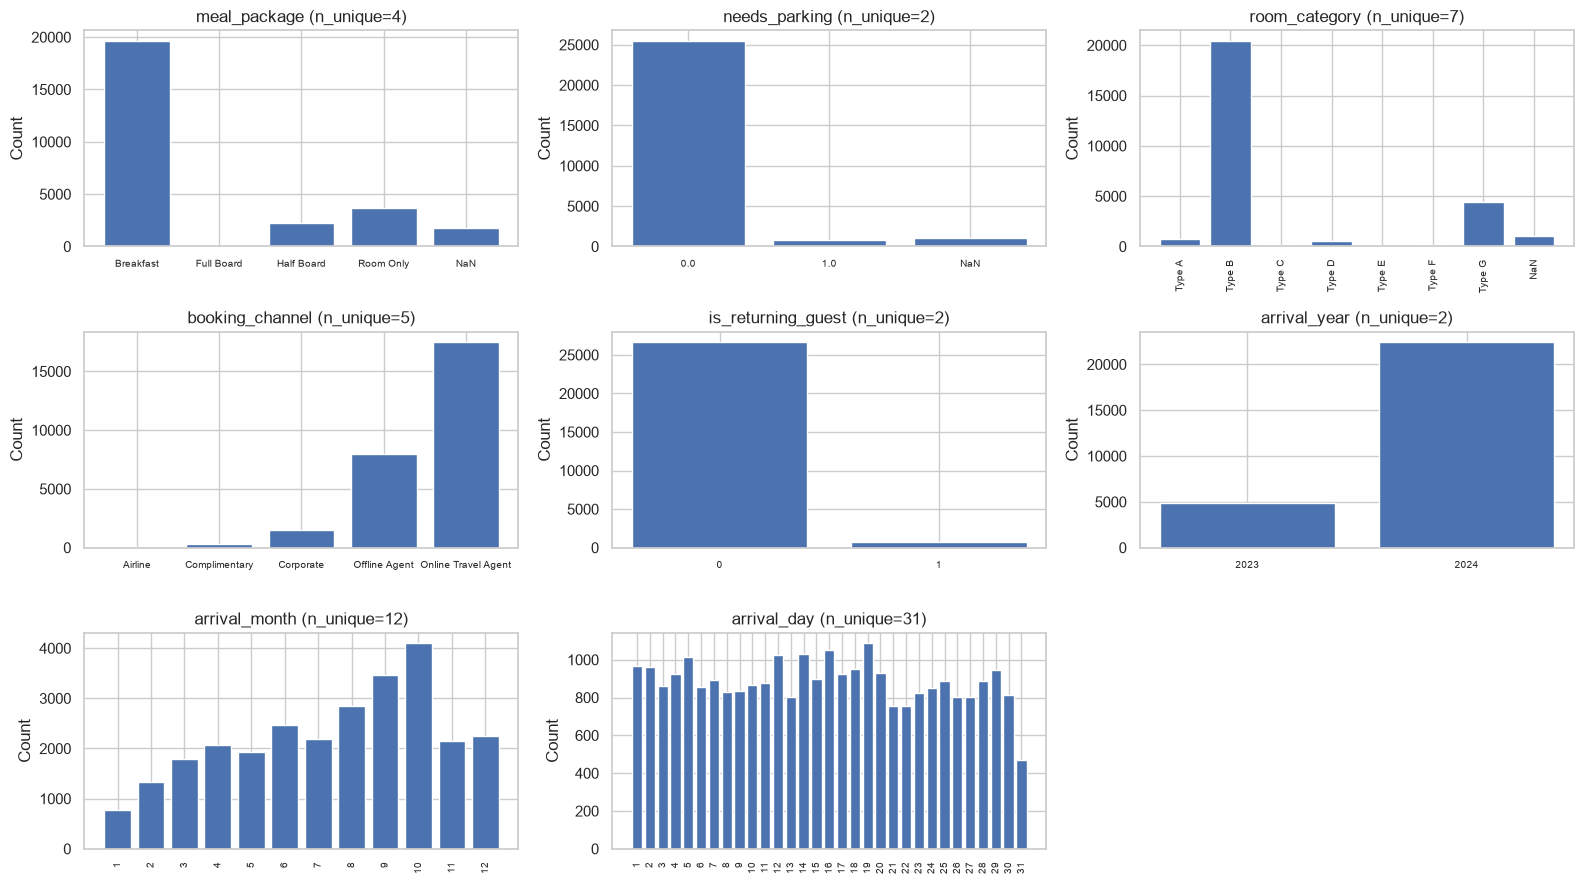

In [25]:
fig, axes = plt.subplots(NROWS_CAT, GRID_NCOLS, figsize=(16, 3.0 * NROWS_CAT))
axes = axes.flatten()

for i, col in enumerate(CAT_COLS):
    vc = train_df[col].value_counts(dropna=False).sort_index()
    x_labels = [str(v) if pd.notna(v) else "NaN" for v in vc.index]
    axes[i].bar(x_labels, vc.values, color="#4C72B0")
    axes[i].set_title(f"{col} (n_unique={train_df[col].nunique()})")
    axes[i].set_ylabel("Count")
    axes[i].tick_params(axis="x", rotation=90 if len(x_labels) > 6 else 0, labelsize=7)

for j in range(N_CAT, len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

### Fitur Numerik vs Target

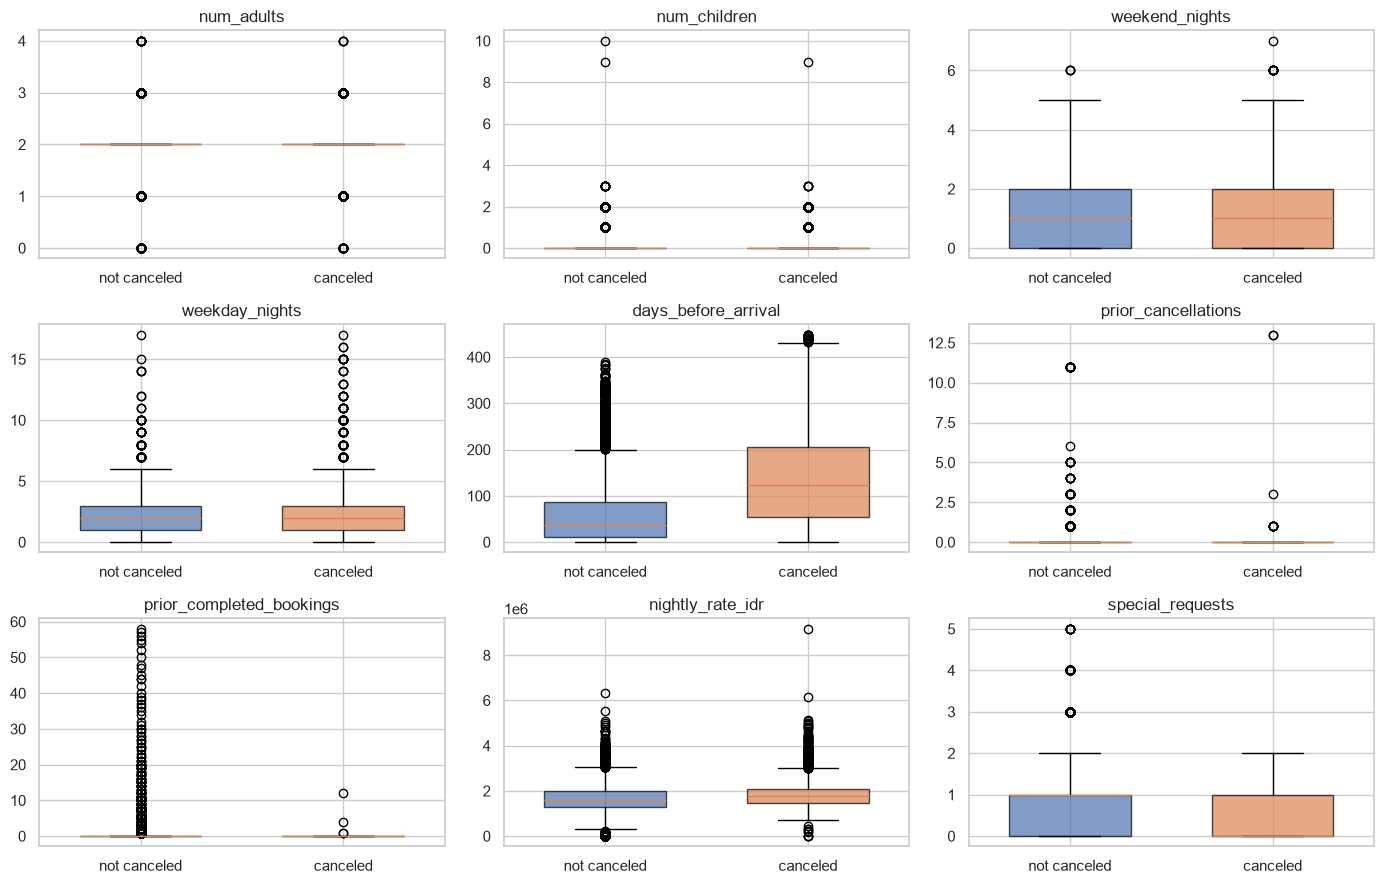

In [26]:
class_labels = sorted(train_df[CFG.TARGET].unique())
label_map = {0: "not canceled", 1: "canceled"}

fig, axes = plt.subplots(NROWS_NUM, GRID_NCOLS, figsize=(14, 3.0 * NROWS_NUM))
axes = axes.flatten()

for i, col in enumerate(NUM_COLS):
    groups = [train_df.loc[train_df[CFG.TARGET] == c, col].dropna() for c in class_labels]
    bp = axes[i].boxplot(groups, patch_artist=True, widths=0.6)
    for patch, color in zip(bp["boxes"], ["#4C72B0", "#DD8452"]):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    axes[i].set_xticks(range(1, len(class_labels) + 1))
    axes[i].set_xticklabels([label_map.get(c, str(c)) for c in class_labels])
    axes[i].set_title(col)

for j in range(N_NUM, len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

### Fitur Kategorikal vs Target

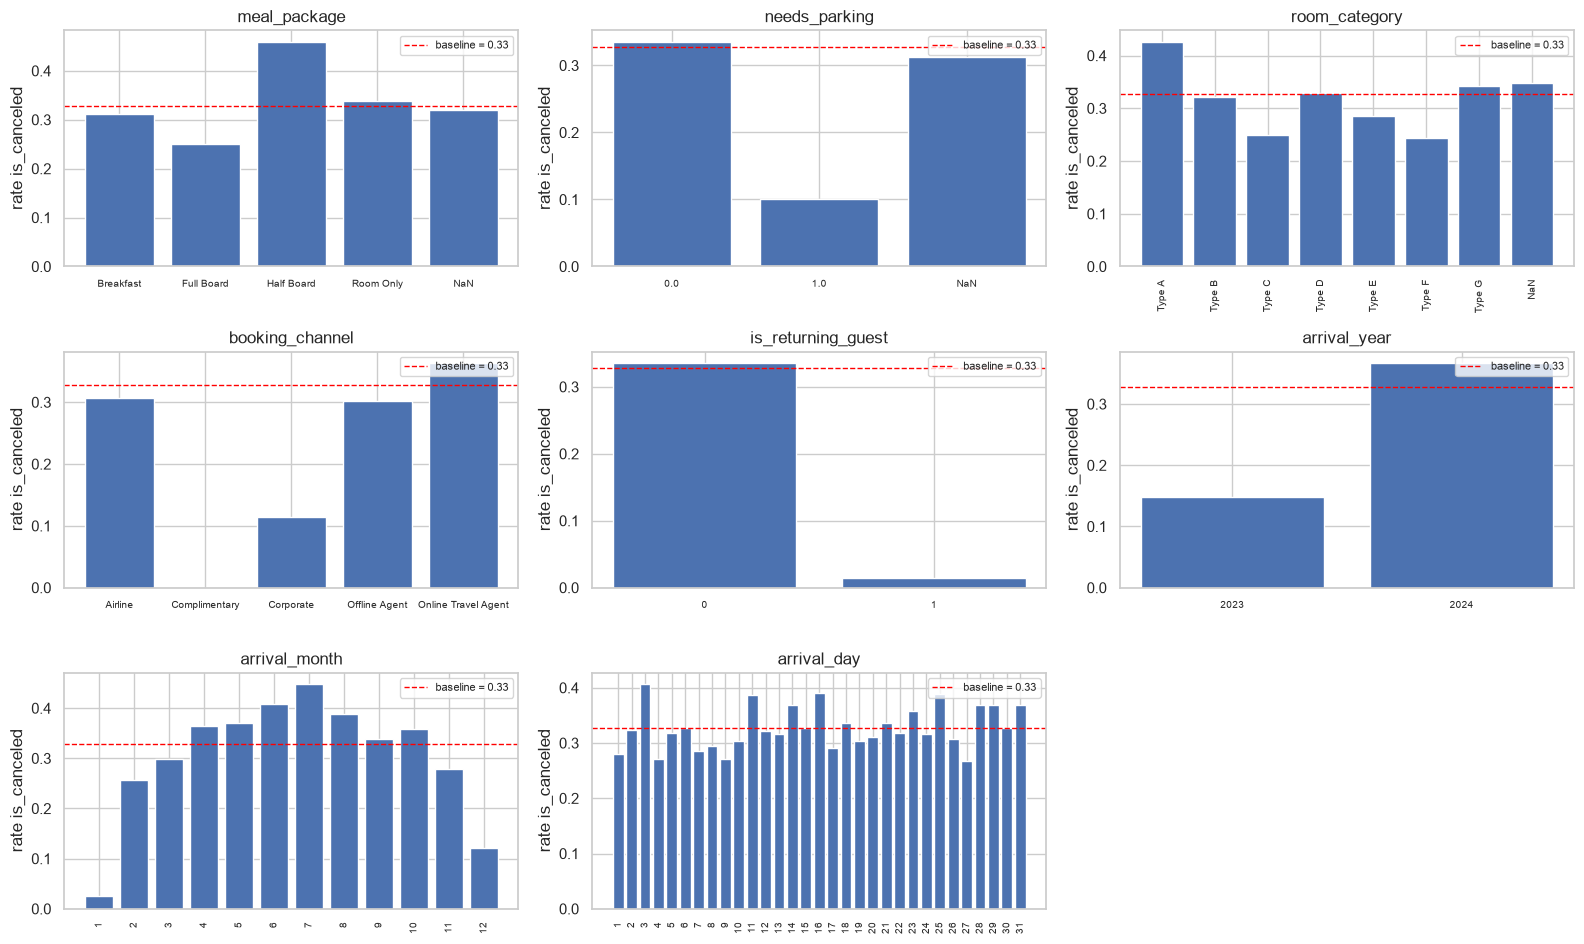

In [27]:
baseline = train_df[CFG.TARGET].mean()

fig, axes = plt.subplots(NROWS_CAT, GRID_NCOLS, figsize=(16, 3.2 * NROWS_CAT))
axes = axes.flatten()

for i, col in enumerate(CAT_COLS):
    rate = train_df.groupby(col, dropna=False)[CFG.TARGET].mean().sort_index()
    x_labels = [str(v) if pd.notna(v) else "NaN" for v in rate.index]
    axes[i].bar(x_labels, rate.values, color="#4C72B0")
    axes[i].axhline(baseline, color="red", linestyle="--", linewidth=1,
                    label=f"baseline = {baseline:.2f}")
    axes[i].set_title(col)
    axes[i].set_ylabel(f"rate {CFG.TARGET}")
    axes[i].legend(fontsize=8, loc="upper right")
    axes[i].tick_params(axis="x", rotation=90 if len(x_labels) > 6 else 0, labelsize=7)

for j in range(N_CAT, len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

### Korelasi Antar Fitur Numerik

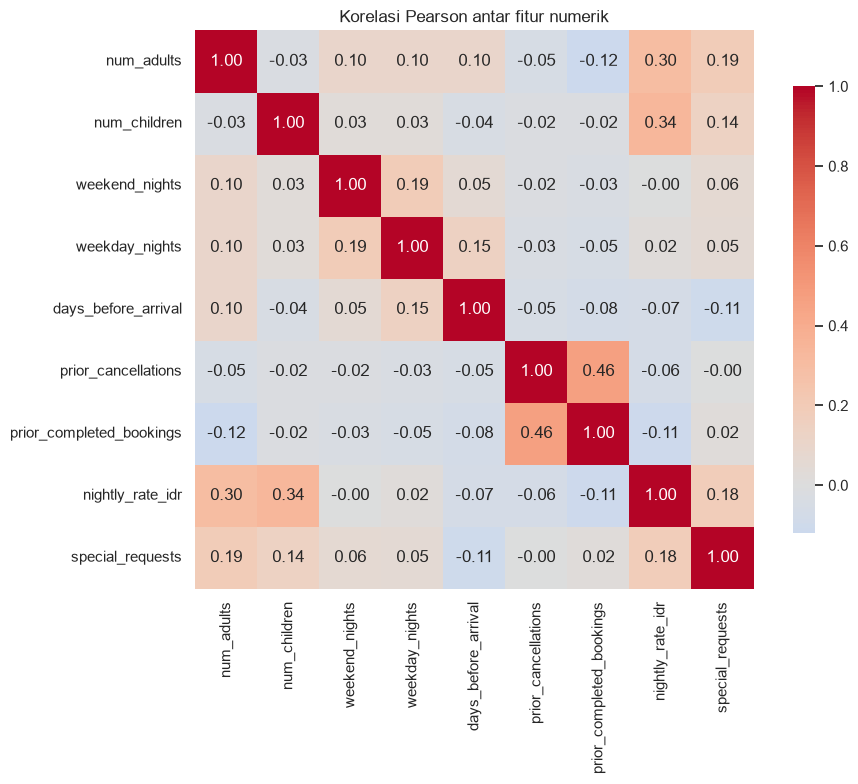

Top 5 pasangan paling berkorelasi:
prior_cancellations  prior_completed_bookings    0.464
num_children         nightly_rate_idr            0.339
num_adults           nightly_rate_idr            0.300
weekend_nights       weekday_nights              0.189
num_adults           special_requests            0.187


In [28]:
corr_matrix = train_df[NUM_COLS].corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f",
            cmap="coolwarm", center=0, square=True,
            cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Korelasi Pearson antar fitur numerik")
plt.tight_layout()
plt.show()

# Top pasangan paling berkorelasi (di luar diagonal)
corr_abs = corr_matrix.abs()
mask_upper = np.triu(np.ones_like(corr_abs, dtype=bool), k=1)
top_pairs = corr_abs.where(mask_upper).stack().sort_values(ascending=False)
print("Top 5 pasangan paling berkorelasi:")
print(top_pairs.head(5).round(3).to_string())

## Verify Data Quality

This part covers completeness, consistency, and the validity of values.

In [29]:
print("=== Missing values per kolom ===")
train_missing = train_df.isna().sum().to_frame("train")
test_missing = test_df.isna().sum().to_frame("test")
missing_summary = train_missing.join(test_missing, how="outer")
missing_summary["train_pct"] = (missing_summary["train"] / len(train_df) * 100).round(2)
missing_summary["test_pct"] = (missing_summary["test"] / len(test_df) * 100).round(2)
display(
    missing_summary[missing_summary[["train", "test"]].sum(axis=1) > 0]
    .sort_values("train", ascending=False)
)

missing_per_row = train_df.isna().sum(axis=1)

print("\nDistribusi jumlah missing per baris (train):")
display(missing_per_row.value_counts().sort_index().to_frame("count"))
print(f"Max missing per baris: {missing_per_row.max()}")

# Berapa baris dengan missing "berat"?
for th in [3, 5, 7]:
    n = (missing_per_row >= th).sum()
    print(f"Baris dengan ≥{th} missing: {n} ({n/len(train_df)*100:.2f}%)")

print("\n=== Duplikasi ===")
print(f"Duplikasi baris train: {train_df.duplicated().sum()}")
print(f"Duplikasi baris test : {test_df.duplicated().sum()}")
print(f"id unik di train: {train_df['id'].is_unique}")
print(f"id unik di test : {test_df['id'].is_unique}")
print(f"id overlap train-test: {len(set(train_df['id']) & set(test_df['id']))}")

print("\n=== Dtype train vs test ===")
common_cols = [c for c in train_df.columns if c != CFG.TARGET]
dtype_match = train_df[common_cols].dtypes == test_df[common_cols].dtypes
n_match, n_total = int(dtype_match.sum()), len(dtype_match)
if dtype_match.all():
    print(f"{n_match}/{n_total} kolom identik")
else:
    print(f"{n_match}/{n_total} kolom match")
    display(dtype_match[~dtype_match].to_frame("match"))

print("\n=== Kategori unseen di test ===")
unseen_report = {}
for col in CAT_COLS:
    unseen = set(test_df[col].dropna().unique()) - set(train_df[col].dropna().unique())
    if unseen:
        unseen_report[col] = sorted(unseen)

if unseen_report:
    print(f"{len(unseen_report)}/{len(CAT_COLS)} fitur punya kategori baru di test:")
    for col, vals in unseen_report.items():
        print(f"  - {col}: {vals}")
else:
    print(f"{len(CAT_COLS)}/{len(CAT_COLS)} fitur: semua kategori test ada di train")


=== Missing values per kolom ===


,train,test,train_pct,test_pct
num_children,3035,747.0,11.09,10.91
special_requests,2500,593.0,9.13,8.66
nightly_rate_idr,2038,540.0,7.45,7.89
meal_package,1760,442.0,6.43,6.46
days_before_arrival,1123,290.0,4.10,4.24
needs_parking,1082,247.0,3.95,3.61
room_category,1002,242.0,3.66,3.54
num_adults,809,180.0,2.96,2.63



Distribusi jumlah missing per baris (train):


,count
0,16636
1,8478
2,1933
3,301
4,23
5,2


Max missing per baris: 5
Baris dengan ≥3 missing: 326 (1.19%)
Baris dengan ≥5 missing: 2 (0.01%)
Baris dengan ≥7 missing: 0 (0.00%)

=== Duplikasi ===
Duplikasi baris train: 0
Duplikasi baris test : 0
id unik di train: True
id unik di test : True
id overlap train-test: 0

=== Dtype train vs test ===
18/18 kolom identik

=== Kategori unseen di test ===
8/8 fitur: semua kategori test ada di train


---

# Training and Validation Split <a name="4"></a>

---

The split comes before data preparation so that validation data stays unseen. Only `train.csv` is split, and `test.csv` serves the Kaggle submission alone.

In [30]:
if CFG.TARGET not in train_df.columns:
    raise KeyError(f"Kolom target '{CFG.TARGET}' tidak ditemukan di train.csv.")

# Split dilakukan sebelum fitting preprocessing agar validation tetap unseen
train_set, val_set = train_test_split(
    train_df,
    test_size=CFG.VALIDATION_SIZE,
    random_state=CFG.SEED,
    stratify=train_df[CFG.TARGET]
)

train_set = train_set.reset_index(drop=True)
val_set = val_set.reset_index(drop=True)

print(f"Training set   : {train_set.shape}")
print(f"Validation set : {val_set.shape}")
print("\nDistribusi target training:")
print(train_set[CFG.TARGET].value_counts(normalize=True).sort_index())
print("\nDistribusi target validation:")
print(val_set[CFG.TARGET].value_counts(normalize=True).sort_index())

split_summary = pd.DataFrame({
    "train_count": train_set[CFG.TARGET].value_counts().sort_index(),
    "train_pct":   (train_set[CFG.TARGET].value_counts(normalize=True).sort_index() * 100).round(2),
    "val_count":   val_set[CFG.TARGET].value_counts().sort_index(),
    "val_pct":     (val_set[CFG.TARGET].value_counts(normalize=True).sort_index() * 100).round(2),
})
display(split_summary)

Training set   : (21898, 19)
Validation set : (5475, 19)

Distribusi target training:
is_canceled
0    0.672345
1    0.327655
Name: proportion, dtype: float64

Distribusi target validation:
is_canceled
0    0.672329
1    0.327671
Name: proportion, dtype: float64


,train_count,train_pct,val_count,val_pct
is_canceled,,,,
0,14723,67.23,3681,67.23
1,7175,32.77,1794,32.77


---

# Data Preparation <a name="5"></a>

---

Each process below applies where the data calls for it, and the Insights block under it records the reason for the decision.

Preparation steps may use `sklearn`. Every statistic comes from the training split only, then transforms the other sets.

## Select Data

Selection decides which records and attributes stay in the analysis.

In [31]:
target_col = CFG.TARGET
id_col = "id"

train_ids = train_set[id_col].copy()
val_ids = val_set[id_col].copy()
test_ids = test_df[id_col].copy()

drop_cols = [id_col, "arrival_year", "arrival_day"]

y_train = train_set[target_col].copy()
y_val = val_set[target_col].copy()

X_train = train_set.drop(columns=drop_cols + [target_col], errors="ignore").copy()
X_val = val_set.drop(columns=drop_cols + [target_col], errors="ignore").copy()

X_test = test_df.drop(columns=drop_cols, errors="ignore").copy()

X_test = X_test.reindex(columns=X_train.columns)

CAT_COLS = [c for c in CAT_COLS if c in X_train.columns]

print("Kolom yang dihapus:", drop_cols)
print("Sisa kolom numerik :", len(NUM_COLS))
print("Sisa kolom kategorikal :", CAT_COLS)
print("\nFitur training:", X_train.shape)
print("Fitur validation:", X_val.shape)
print("Fitur test:", X_test.shape)

Kolom yang dihapus: ['id', 'arrival_year', 'arrival_day']
Sisa kolom numerik : 9
Sisa kolom kategorikal : ['meal_package', 'needs_parking', 'room_category', 'booking_channel', 'is_returning_guest', 'arrival_month']

Fitur training: (21898, 15)
Fitur validation: (5475, 15)
Fitur test: (6844, 15)


> Kolom id dipisahkan karena hanya berfungsi sebagai identifier unik untuk submission Kaggle. Kolom arrival_year dibuang karena distribusinya sangat tidak seimbang (82% data berada di tahun 2024) sehingga hampir konstan dan tidak prediktif. Kolom arrival_day dibuang karena kardinalitasnya yang tinggi (31 kategori) dan tidak menunjukkan tren pembatalan yang jelas (hanya noise). Kolom arrival_month tetap dipertahankan karena menyimpan informasi musiman yang relevan. List CAT_COLS disinkronkan agar tidak memuat kolom yang sudah dihapus.

## Clean Data

Cleaning raises data quality to the level the chosen models need.

### Missing Values

This part covers missing values, if any.

In [32]:
# Kolom yang seluruh nilainya kosong dan tidak memberikan informasi
all_missing_cols = X_train.columns[X_train.isna().all()].tolist()
print("Kolom seluruhnya missing:", all_missing_cols)

X_train.drop(columns=all_missing_cols, inplace=True)
X_val.drop(columns=all_missing_cols, inplace=True)
X_test.drop(columns=all_missing_cols, inplace=True)

# Nilai kosong pada kolom lain tidak diisi secara manual di sini.
# Imputasi median/modus akan di-fit hanya pada training set di preparation pipeline.
missing_train = X_train.isna().sum()
display(missing_train[missing_train > 0].sort_values(ascending=False).to_frame("missing_train"))

Kolom seluruhnya missing: []


C:\Users\Infinix\AppData\Local\Temp\ipykernel_15292\552546469.py:5: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  X_train.drop(columns=all_missing_cols, inplace=True)
C:\Users\Infinix\AppData\Local\Temp\ipykernel_15292\552546469.py:6: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  X_val.drop(columns=all_missing_cols, inplace=True)
C:\Users\Infinix\AppData\Local\Temp\ipykernel_15292\552546469.py:7: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  X_test.drop(columns=all_missing_cols, 

,missing_train
num_children,2426
special_requests,2015
nightly_rate_idr,1622
meal_package,1403
needs_parking,885
days_before_arrival,877
room_category,810
num_adults,636


> Keputusan utama pada tahap ini adalah tidak menghapus baris (drop rows) yang memiliki nilai kosong. Berdasarkan analisis di Verify Data Quality, mayoritas baris hanya memiliki 1 hingga 2 nilai kosong, sehingga menghapus baris akan membuang terlalu banyak data. Nilai kosong yang tersisa sengaja dibiarkan dan akan ditangani di langkah ke depannya.

### Duplicates

This part covers repeated records.

In [33]:
# Duplikasi hanya dihapus dari training set. Validation/test tidak dipakai untuk menentukan baris training yang dipertahankan.
duplicate_count = X_train.duplicated().sum()
print("Duplikasi pada training sebelum penghapusan:", duplicate_count)

if duplicate_count:
    keep_mask = ~X_train.duplicated(keep="first")
    X_train = X_train.loc[keep_mask].reset_index(drop=True)
    y_train = y_train.loc[keep_mask].reset_index(drop=True)

print("Ukuran training setelah penghapusan duplikasi:", X_train.shape)

Duplikasi pada training sebelum penghapusan: 49
Ukuran training setelah penghapusan duplikasi: (21849, 15)


### Outliers

This part covers values far from the rest of the data.

In [34]:
continuous_for_iqr = ["nightly_rate_idr", "days_before_arrival"] # ini ntar tinjau lagi
outlier_bounds = {}

for col in continuous_for_iqr:
    q1 = X_train[col].quantile(0.25)
    q3 = X_train[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - CFG.OUTLIER_IQR_FACTOR * iqr
    upper = q3 + CFG.OUTLIER_IQR_FACTOR * iqr
    outlier_bounds[col] = (lower, upper)

    n_outliers = ((X_train[col] < lower) | (X_train[col] > upper)).sum()
    print(f"{col}: {n_outliers} outlier akan di-clip pada rentang [{lower:.2f}, {upper:.2f}]")

def clip_outliers(frame, bounds):
    frame = frame.copy()
    for col, (lower, upper) in bounds.items():
        if col in frame.columns:
            frame[col] = frame[col].clip(lower=lower, upper=upper)
    return frame

X_train = clip_outliers(X_train, outlier_bounds)
X_val = clip_outliers(X_val, outlier_bounds)
X_test = clip_outliers(X_test, outlier_bounds)

# coba nanti domain clipping fitur ga wajar

nightly_rate_idr: 886 outlier akan di-clip pada rentang [317000.00, 3045000.00]
days_before_arrival: 750 outlier akan di-clip pada rentang [-145.00, 287.00]


> Pengecekan outlier menggunakan metode IQR hanya diterapkan pada fitur kontinu (nightly_rate_idr dan days_before_arrival) yang distribusinya sangat right-skewed. Pendekatan IQR tidak diterapkan pada fitur diskrit, biner, atau count (seperti needs_parking, is_returning_guest, num_adults, dan prior_cancellations). Hal ini mempertimbangkan jika diterapkan pada data biner/count, IQR justru akan menghapus sinyal penting (misalnya, tamu yang pernah membatalkan pesanan sebelumnya akan dianggap sebagai outlier dan diubah menjadi 0).

### Data Errors

This part covers wrong types, inconsistent labels, and impossible values.

In [35]:
def correct_data_errors(frame):
    frame = frame.copy()

    # rapikan whitespace pada atribut kategorikal (jaga-jaga ada typo spasi)
    categorical = frame.select_dtypes(include=["object", "category"]).columns
    for col in categorical:
        frame[col] = frame[col].map(
            lambda value: value.strip() if isinstance(value, str) else value
        )

    # daftar kolom yang secara logika tidak boleh negatif
    non_negative_candidates = [
        "num_adults", "num_children", "weekend_nights", "weekday_nights",
        "days_before_arrival", "prior_cancellations", "prior_completed_bookings",
        "nightly_rate_idr", "special_requests"
    ]

    for col in non_negative_candidates:
        if col in frame.columns:
            frame[col] = pd.to_numeric(frame[col], errors="coerce")
            # jika ada nilai negatif (misal -1 hari), ubah jadi NaN
            frame.loc[frame[col] < 0, col] = np.nan

    # tangani nilai janggal (Impossible Values) spesifik dataset
    if "num_adults" in frame.columns:
        frame.loc[frame["num_adults"] == 0, "num_adults"] = np.nan

    return frame

X_train = correct_data_errors(X_train)
X_val = correct_data_errors(X_val)
X_test = correct_data_errors(X_test)

C:\Users\Infinix\AppData\Local\Temp\ipykernel_15292\181144214.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical = frame.select_dtypes(include=["object", "category"]).columns
C:\Users\Infinix\AppData\Local\Temp\ipykernel_15292\181144214.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/d

> 1. Dilakukan pembersihan whitespace (spasi berlebih) pada seluruh fitur kategorikal untuk mencegah kategori ganda (misal: "Breakfast" vs "Breakfast ").

> 2. Daftar kolom yang diperiksa untuk nilai negatif disesuaikan dengan skema dataset kompetisi. Nilai negatif (jika ada) akan diubah menjadi NaN agar ditangani oleh Imputer.

> 3. Penanganan Nilai Mustahil (Impossible Values): Ditemukan 106 baris dengan num_adults == 0. Secara logika bisnis, reservasi hotel tidak mungkin dilakukan tanpa orang dewasa. Oleh karena itu, nilai 0 pada num_adults diubah menjadi NaN agar dapat diimputasi dengan nilai median dari data yang valid, sehingga model tidak belajar dari pola yang salah.

## Construct Data

Construction derives attributes and transforms values for modeling.

### Attribute Construction

<!-- rubric v3: derived columns, rate_per_guest_night -->

This part covers new attributes derived from existing ones.

In [36]:
def construct_attributes(frame):
    frame = frame.copy()
    frame["total_guests"] = frame["num_adults"].fillna(0) + frame["num_children"].fillna(0)
    frame["total_nights"] = frame["weekend_nights"] + frame["weekday_nights"]
    frame["total_cost"] = frame["nightly_rate_idr"] * frame["total_nights"]
    safe_guests = frame["total_guests"].replace(0, 1)
    frame["price_per_guest"] = frame["nightly_rate_idr"] / safe_guests
    #new feature: rasio pembatalan historis
    denom = frame["prior_cancellations"] + frame["prior_completed_bookings"] + 1
    frame["historical_cancel_rate"] = frame["prior_cancellations"] / denom
    #log-transform untuk fitur skewed (agar LR/SVM lebih stabil)
    frame["nightly_rate_idr"] = np.log1p(frame["nightly_rate_idr"])
    frame["days_before_arrival"] = np.log1p(frame["days_before_arrival"])

    return frame

X_train = construct_attributes(X_train)
X_val = construct_attributes(X_val)
X_test = construct_attributes(X_test)

print("Fitur setelah konstruksi:", X_train.shape[1])
display(X_train[["total_guests", "total_nights", "total_cost", "price_per_guest"]].head())

NUM_COLS.extend(["historical_cancel_rate", "total_guests", "total_nights", "total_cost", "price_per_guest"])

Fitur setelah konstruksi: 20


,total_guests,total_nights,total_cost,price_per_guest
0,2.0,2.0,NaN,NaN
1,2.0,3.0,4503000.0,750500.0
2,1.0,2.0,3240000.0,1620000.0
3,2.0,2.0,2838000.0,709500.0
4,2.0,3.0,7008000.0,1168000.0


### Feature Scaling

This part covers normalization to the range 0 to 1 and standardization.

In [37]:
# transformer umum (utk KNN, SVM, LR, DTL)
numeric_transformer_gen = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])

# transformer khusus Naive Bayes (binning, bukan scaling)
numeric_transformer_nb = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("discretizer", KBinsDiscretizer(n_bins=5, encode="ordinal", strategy="quantile"))
])

> Imputasi data numerik menggunakan median untuk semua fitur numerik karena tahan terhadap outlier dan lebih masuk akal untuk fitur count (misal: imputasi 2 orang dewasa lebih wajar daripada 1.84 orang). Namun, khusus Naive Bayes fitur numerik diubah menjadi data kategorikal (diskrit) menggunakan KBinsDiscretizer karena Naive Bayes Categorical tidak dapat memproses angka desimal kontinu (hasil scaling). Scaling menggunakan RobustScaler karena data kita banyak mengandung outlier ekstrem dan right-skewed (seperti nightly_rate_idr dan days_before_arrival), RobustScaler yang berbasis Median dan IQR akan menormalkan skala tanpa tertarik oleh nilai ekstrem tersebut.

### Encoding

This part covers the numeric representation of categorical attributes.

In [38]:
from sklearn.preprocessing import OrdinalEncoder


categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

#encoder khusus untuk NB
categorical_transformer_nb = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))
])

> Imputasi data kategorikal menggunakan modus. Encodingnya menggunakan one hot encoder.

### Dimensionality Reduction

This part covers fewer dimensions that keep the meaning of the data.

In [39]:
# Secara default dinonaktifkan agar interpretabilitas fitur hasil encoding tetap terjaga dan semua model menerima fitur yg sama
if CFG.APPLY_PCA:
    dimensionality_reducer = PCA(
        n_components=CFG.PCA_VARIANCE,
        random_state=CFG.SEED
    )
else:
    dimensionality_reducer = None

print("PCA aktif:", dimensionality_reducer is not None)

PCA aktif: False


> Transformasi Dimensi (PCA) sengaja dinonaktifkan (APPLY_PCA = False). Meskipun PCA dapat mempercepat komputasi, penggunaannya tidak cocok untuk kasus ini. Pertama, jumlah fitur kita masih wajar (< 60 fitur setelah One-Hot Encoding). Kedua, algoritma Naive Bayes (Categorical) dan Decision Tree sangat bergantung pada fitur asli yang diskrit dan terpisah (axis-aligned). Jika PCA diterapkan, fitur akan berubah menjadi nilai kontinu hasil kombinasi linear (principal components), yang akan merusak asumsi Naive Bayes dan memaksa Decision Tree membentuk oblique splits (pohon yang jauh lebih dalam dan rawan overfitting). Selain itu, dengan mempertahankan fitur asli, kita mempertahankan interpretabilitas model (bisa tahu fitur mana yang paling mempengaruhi pembatalan).

## Class Balance

This part covers the proportion of each class in the training data.

In [40]:
balance_df = pd.DataFrame({
    "Train Count": y_train.value_counts().sort_index(),
    "Train (%)": (y_train.value_counts(normalize=True).sort_index() * 100).round(2),
    "Val Count": y_val.value_counts().sort_index(),
    "Val (%)": (y_val.value_counts(normalize=True).sort_index() * 100).round(2)
})
balance_df.index = ["Not Canceled (0)", "Canceled (1)"]

display(balance_df)

,Train Count,Train (%),Val Count,Val (%)
Not Canceled (0),14690,67.23,3681,67.23
Canceled (1),7159,32.77,1794,32.77


> Meskipun termasuk dalam kategori moderate imbalance, strategi Random Oversampling sengaja dinonaktifkan (APPLY_RANDOM_OVERSAMPLING = False) untuk mencegah risiko overfitting pada model berbasis jarak (KNN) dan pohon (Decision Tree). Sebagai gantinya, penanganan imbalanced data akan difokuskan pada pemilihan metrik evaluasi yang tepat (menggunakan Macro F1-Score dan Recall untuk kelas minoritas), bukan sekadar akurasi. Jika di tahap evaluasi model kelas minoritas berkinerja buruk, teknik oversampling akan diujicobakan di bagian Improvements.

## Format Data

Formatting produces the structure the models read, such as a numeric matrix.

In [41]:
# target dipastikan memiliki nilai dan fitur train/validation/test dengan kolom sama.
if y_train.isna().any() or y_val.isna().any():
    raise ValueError("Target mengandung missing values; periksa dataset sebelum modeling.")

# Urutan fitur disamakan sebelum transformasi.
X_val = X_val.reindex(columns=X_train.columns)
X_test = X_test.reindex(columns=X_train.columns)

print("Target training:", y_train.shape)
print("Target validation:", y_val.shape)
print("Jumlah fitur sebelum encoding:", X_train.shape[1])

Target training: (21849,)
Target validation: (5475,)
Jumlah fitur sebelum encoding: 20


---

# Preparation Pipeline <a name="6"></a>

---

<!-- rubric v3: fitted steps, fitted_prep_steps -->

The pipeline combines the preparation steps so they run in one consistent order.

In [42]:
# rakit kolom transformer
preprocessor_gen = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer_gen, NUM_COLS),
        ("cat", categorical_transformer, CAT_COLS)
    ],
    remainder="drop",
    verbose_feature_names_out=False
)

preprocessor_nb = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer_nb, NUM_COLS),
        ("cat", categorical_transformer_nb, CAT_COLS)
    ],
    remainder="drop",
    verbose_feature_names_out=False
)

# helper untuk fit_transform, transform, dan mengubah output jadi DataFrame
def process_data(pipeline, X_tr, X_v, X_te):
    X_tr_arr = pipeline.fit_transform(X_tr)
    X_v_arr = pipeline.transform(X_v)
    X_te_arr = pipeline.transform(X_te)
    cols = pipeline.get_feature_names_out()

    df_tr = pd.DataFrame(X_tr_arr, columns=cols, index=X_tr.index)
    df_v = pd.DataFrame(X_v_arr, columns=cols, index=X_v.index)
    df_te = pd.DataFrame(X_te_arr, columns=cols)
    return df_tr, df_v, df_te

# eksekusi pipeline
print("Memproses data untuk Model Umum (KNN, SVM, LR, DTL)...")
X_train_gen, X_val_gen, X_test_gen = process_data(preprocessor_gen, X_train, X_val, X_test)

print("Memproses data untuk Naive Bayes (Binning)...")
X_train_nb, X_val_nb, X_test_nb = process_data(preprocessor_nb, X_train, X_val, X_test)

# handling target n oversampling
y_train_processed = y_train.reset_index(drop=True)
y_val_processed = y_val.reset_index(drop=True)

if CFG.APPLY_RANDOM_OVERSAMPLING:
    print("Menerapkan Random Oversampling...")
    counts = y_train_processed.value_counts()
    majority_count = counts.max()
    sampled_indices = []
    rng = np.random.default_rng(CFG.SEED)

    for label, count in counts.items():
        label_indices = np.flatnonzero(y_train_processed.to_numpy() == label)
        sampled_indices.extend(label_indices.tolist())
        if count < majority_count:
            sampled_indices.extend(
                rng.choice(label_indices, size=majority_count-count, replace=True).tolist()
            )
    rng.shuffle(sampled_indices)

    # terapkan indeks yang sama ke data general dan NB
    X_train_gen = X_train_gen.iloc[sampled_indices].reset_index(drop=True)
    X_train_nb = X_train_nb.iloc[sampled_indices].reset_index(drop=True)
    y_train_processed = y_train_processed.iloc[sampled_indices].reset_index(drop=True)


print("\n=== Shape Data Model Umum (Scaled) ===")
print(f"Train: {X_train_gen.shape} | Val: {X_val_gen.shape} | Test: {X_test_gen.shape}")

print("\n=== Shape Data Naive Bayes (Binned) ===")
print(f"Train: {X_train_nb.shape} | Val: {X_val_nb.shape} | Test: {X_test_nb.shape}")

print(f"\nTarget Train: {y_train_processed.shape} | Target Val: {y_val_processed.shape}")

Memproses data untuk Model Umum (KNN, SVM, LR, DTL)...


Memproses data untuk Naive Bayes (Binning)...

=== Shape Data Model Umum (Scaled) ===
Train: (21849, 46) | Val: (5475, 46) | Test: (6844, 46)

=== Shape Data Naive Bayes (Binned) ===
Train: (21849, 20) | Val: (5475, 20) | Test: (6844, 20)

Target Train: (21849,) | Target Val: (5475,)


C:\Users\Infinix\AppData\Roaming\Python\Python314\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 0 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\Infinix\AppData\Roaming\Python\Python314\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 1 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\Infinix\AppData\Roaming\Python\Python314\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(
C:\Users\Infinix\AppData\Roaming\Python\Python314\site-packages\sklearn\preprocessing\_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 3 are removed. Consider decreasing the number of bins.
  war

---

# Modeling and Validation <a name="7"></a>

---

The target is `is_canceled`. The models here are implemented from scratch, with math libraries such as NumPy.

In [59]:
best_models = {} # menyimpan model terbaik tiap algoritma
best_predictions = {} # menyimpan prediksi val dari model terbaik

def evaluate_model(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "F1-Score": f1_score(y_true, y_pred, average="macro", zero_division=0),
    }

## K-Nearest Neighbors

<!-- rubric v3: pairwise distances, val_neighbor_dists -->

This part covers the nearest neighbor classifier and its validation.

In [60]:
X_train_knn = X_train_gen.to_numpy(dtype=float)
X_val_knn = X_val_gen.to_numpy(dtype=float)

knn_model = KNN(k=5, distance_metric="euclidean", weights="uniform")
knn_model.fit(X_train_knn, y_train_processed)

y_val_pred_knn = knn_model.predict(X_val_knn)

print("=== K-Nearest Neighbors (K=5) ===")
display(pd.Series(evaluate_model(y_val_processed, y_val_pred_knn), name="Validation Score").to_frame())
print("\nClassification Report:")
print(classification_report(y_val_processed, y_val_pred_knn, zero_division=0))
print("Confusion Matrix:")
display(pd.DataFrame(
    confusion_matrix(y_val_processed, y_val_pred_knn),
    index=[f"Actual {label}" for label in knn_model.classes_],
    columns=[f"Predicted {label}" for label in knn_model.classes_],
))

best_models["KNN"] = knn_model
best_predictions["KNN"] = y_val_pred_knn

=== K-Nearest Neighbors (K=5) ===


,Validation Score
Accuracy,0.827763
Precision,0.805391
Recall,0.801187
F1-Score,0.803207



Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.88      0.87      3681
           1       0.74      0.72      0.73      1794

    accuracy                           0.83      5475
   macro avg       0.81      0.80      0.80      5475
weighted avg       0.83      0.83      0.83      5475

Confusion Matrix:


,Predicted 0,Predicted 1
Actual 0,3233,448
Actual 1,495,1299


## Decision Tree Learning

This part covers one chosen variant, which is ID3, C4.5, or CART, and its validation.

In [54]:
X_train_dt = X_train_gen
X_val_dt = X_val_gen

dt_model = DecisionTreeCART(max_depth=8, min_samples_split=10, min_samples_leaf=5)
dt_model.fit(X_train_dt, y_train_processed)

y_val_pred_dt = dt_model.predict(X_val_dt)

print("=== Decision Tree (CART) | max_depth=8 ===")
display(pd.Series(evaluate_model(y_val_processed, y_val_pred_dt), name="Validation Score").to_frame())
print("\nClassification Report:")
print(classification_report(y_val_processed, y_val_pred_dt, zero_division=0))
print("Confusion Matrix:")
display(pd.DataFrame(
    confusion_matrix(y_val_processed, y_val_pred_dt),
    index=[f"Actual {label}" for label in dt_model.classes_],
    columns=[f"Predicted {label}" for label in dt_model.classes_],
))

best_models["Decision Tree"] = dt_model
best_predictions["Decision Tree"] = y_val_pred_dt

KeyboardInterrupt: 

## Logistic Regression

This part covers the model with L1, L2, and Elastic Net regularization.

In [55]:
X_train_lr = X_train_gen.to_numpy(dtype=float)
X_val_lr = X_val_gen.to_numpy(dtype=float)

lr_configs = {
    "L1": {"penalty": "l1", "lambda1": 10.0, "lambda2": 0.0},   #lambda dinaikkin dari 0.01 ke 10.0
    "L2": {"penalty": "l2", "lambda1": 0.0, "lambda2": 10.0},   #lambda dinaikkin dari 0.01 ke 10.0
    "Elastic Net": {"penalty": "elastic", "lambda1": 10.0, "lambda2": 10.0},
}

lr_results, lr_temp_models, lr_temp_preds = [], {}, {}

for name, params in lr_configs.items():
    model = LogisticReg(
        learning_rate=0.01, n_epochs=200, penalty=params["penalty"],
        lambda1=params["lambda1"], lambda2=params["lambda2"],
        batch_size=256, shuffle=True, random_state=CFG.SEED,
    )
    model.fit(X_train_lr, y_train_processed)
    pred = model.predict(X_val_lr)

    metrics = evaluate_model(y_val_processed, pred)
    metrics["Config"] = name
    lr_results.append(metrics)

    lr_temp_models[name] = model
    lr_temp_preds[name] = pred

lr_df = pd.DataFrame(lr_results).set_index("Config")
display(lr_df)

best_lr_name = lr_df["F1-Score"].idxmax()
print(f"\nModel LR Terbaik: {best_lr_name}")
print(classification_report(y_val_processed, lr_temp_preds[best_lr_name], zero_division=0))

best_models["Logistic Regression"] = lr_temp_models[best_lr_name]
best_predictions["Logistic Regression"] = lr_temp_preds[best_lr_name]

,Accuracy,Precision,Recall,F1-Score
Config,,,,
L1,0.672329,0.336164,0.500000,0.402031
L2,0.672329,0.336164,0.500000,0.402031
Elastic Net,0.649863,0.379190,0.485293,0.400757



Model LR Terbaik: L1
              precision    recall  f1-score   support

           0       0.67      1.00      0.80      3681
           1       0.00      0.00      0.00      1794

    accuracy                           0.67      5475
   macro avg       0.34      0.50      0.40      5475
weighted avg       0.45      0.67      0.54      5475



## Support Vector Machine

<!-- rubric v3: total slack, slack_total -->

This part covers the linear, polynomial, and Gaussian kernels.

In [56]:
X_train_svm = X_train_gen.to_numpy(dtype=float)
X_val_svm = X_val_gen.to_numpy(dtype=float)

svm_kernels = ["linear", "poly", "rbf"]
svm_results, svm_temp_models, svm_temp_preds = [], {}, {}

for kernel_name in svm_kernels:
    model = SVM(
        kernel=kernel_name, C=1.0, degree=3, gamma="scale", coef0=1.0,
        lr=0.01 if kernel_name == "linear" else 0.005, epochs=50,
        max_kernel_samples=10000, random_state=CFG.SEED,
    )
    model.fit(X_train_svm, y_train_processed)
    pred = model.predict(X_val_svm)

    metrics = evaluate_model(y_val_processed, pred)
    metrics["Kernel"] = kernel_name
    metrics["Total Slack"] = model.slack_total
    svm_results.append(metrics)

    svm_temp_models[kernel_name] = model
    svm_temp_preds[kernel_name] = pred

svm_df = pd.DataFrame(svm_results).set_index("Kernel")
display(svm_df)

best_svm_name = svm_df["F1-Score"].idxmax()
print(f"\nModel SVM Terbaik: {best_svm_name.upper()}")
print(classification_report(y_val_processed, svm_temp_preds[best_svm_name], zero_division=0))

best_models["SVM"] = svm_temp_models[best_svm_name]
best_predictions["SVM"] = svm_temp_preds[best_svm_name]

,Accuracy,Precision,Recall,F1-Score,Total Slack
Kernel,,,,,
linear,0.781553,0.753153,0.741104,0.746295,11406.857418
poly,0.819726,0.804754,0.773208,0.785089,4384.327875
rbf,0.809863,0.800032,0.751871,0.767369,4505.575325



Model SVM Terbaik: POLY
              precision    recall  f1-score   support

           0       0.84      0.91      0.87      3681
           1       0.77      0.64      0.70      1794

    accuracy                           0.82      5475
   macro avg       0.80      0.77      0.79      5475
weighted avg       0.82      0.82      0.81      5475



## Naive Bayes

This part covers the Naive Bayes classifier and its validation.

In [57]:
X_train_nb_model = X_train_nb
X_val_nb_model = X_val_nb

nb_alphas = [0.5, 1.0, 2.0]
nb_results, nb_temp_models, nb_temp_preds = [], {}, {}

for alpha in nb_alphas:
    model = NaiveBayes(alpha=alpha)
    model.fit(X_train_nb_model, y_train_processed)
    pred = model.predict(X_val_nb_model)

    metrics = evaluate_model(y_val_processed, pred)
    metrics["Alpha"] = alpha
    nb_results.append(metrics)

    nb_temp_models[alpha] = model
    nb_temp_preds[alpha] = pred

nb_df = pd.DataFrame(nb_results).set_index("Alpha")
display(nb_df)

best_nb_alpha = nb_df["F1-Score"].idxmax()
print(f"\nModel Naive Bayes Terbaik: Alpha = {best_nb_alpha}")
print(classification_report(y_val_processed, nb_temp_preds[best_nb_alpha], zero_division=0))

best_models["Naive Bayes"] = nb_temp_models[best_nb_alpha]
best_predictions["Naive Bayes"] = nb_temp_preds[best_nb_alpha]

,Accuracy,Precision,Recall,F1-Score
Alpha,,,,
0.5,0.747580,0.713844,0.715411,0.714606
1.0,0.747763,0.714061,0.715689,0.714853
2.0,0.747580,0.713844,0.715411,0.714606



Model Naive Bayes Terbaik: Alpha = 1.0
              precision    recall  f1-score   support

           0       0.81      0.81      0.81      3681
           1       0.61      0.62      0.62      1794

    accuracy                           0.75      5475
   macro avg       0.71      0.72      0.71      5475
weighted avg       0.75      0.75      0.75      5475



## Model Evaluation

<!-- figure palette: #6d2fa3 -->

This part compares the validation results of all models.

In [ ]:
comparison_results = []

for model_name, preds in best_predictions.items():
    metrics = evaluate_model(y_val_processed, preds)
    metrics["Model"] = model_name
    comparison_results.append(metrics)

final_comparison_df = pd.DataFrame(comparison_results).set_index("Model")
final_comparison_df = final_comparison_df.sort_values("F1-Score", ascending=False)

print("=== PERBANDINGAN PERFORMA SELURUH MODEL ===")
display(final_comparison_df.round(4))

=== PERBANDINGAN PERFORMA SELURUH MODEL ===


,Accuracy,Precision,Recall,F1-Score
Model,,,,
KNN,0.8307,0.8099,0.8012,0.8052
SVM,0.8080,0.7893,0.7611,0.7718
Logistic Regression,0.7980,0.7763,0.7505,0.7603
Naive Bayes,0.7467,0.7138,0.7194,0.7163


## Improvements (Optional)

This part covers hyperparameter tuning, cross-validation, and further visualization.

=== 1. HYPERPARAMETER TUNING: KNN ===


Weights,distance,uniform
K,,
3,0.813951,0.806685
5,0.816145,0.805209
7,0.818657,0.805757
9,0.821179,0.803251
11,0.824219,0.802965
15,0.820074,0.802509


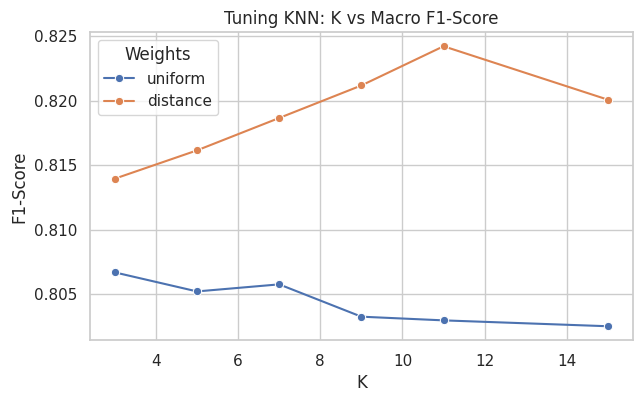


=== 2. MEMBUKTIKAN EFEK REGULARISASI LOGISTIC REGRESSION ===
Hasil LR (L2 dengan Lambda=1.0):


,Score
Accuracy,0.796347
Precision,0.780763
Recall,0.737819
F1-Score,0.751682



=== 3. CROSS-VALIDATION (5-FOLD) UNTUK MODEL TERBAIK ===
F1-Score per fold: [0.8116, 0.8033, 0.8129, 0.7994, 0.8025]
Rata-rata F1-Score CV: 0.8059 ± 0.0053

=== 4. THRESHOLD TUNING UNTUK KELAS MINORITAS (CANCELED) ===


,F1-Score,Recall (Canceled)
Threshold,,
0.3,0.757726,0.769788
0.4,0.762304,0.669454
0.5,0.751682,0.568004
0.6,0.718991,0.458194
0.7,0.676809,0.362319


In [ ]:
from sklearn.model_selection import StratifiedKFold
import matplotlib.pyplot as plt
import seaborn as sns

print("=== HYPERPARAMETER TUNING: KNN ===")
k_values = [3, 5, 7, 9, 11, 15]
knn_results = []

for k in k_values:
    for w in ["uniform", "distance"]:
        model = KNN(k=k, distance_metric="euclidean", weights=w)
        model.fit(X_train_gen.to_numpy(dtype=float), y_train_processed)
        pred = model.predict(X_val_gen.to_numpy(dtype=float))

        f1 = f1_score(y_val_processed, pred, average="macro", zero_division=0)
        knn_results.append({"K": k, "Weights": w, "F1-Score": f1})

knn_tuning_df = pd.DataFrame(knn_results)
knn_pivot = knn_tuning_df.pivot(index="K", columns="Weights", values="F1-Score")
display(knn_pivot)

plt.figure(figsize=(7, 4))
sns.lineplot(data=knn_tuning_df, x="K", y="F1-Score", hue="Weights", marker="o")
plt.title("Tuning KNN: K vs Macro F1-Score")
plt.grid(True)
plt.show()

print("\n=== MEMBUKTIKAN EFEK REGULARISASI LOGISTIC REGRESSION ===")
lr_improved = LogisticReg(penalty="l2", lambda2=1.0, n_epochs=200, random_state=CFG.SEED)
lr_improved.fit(X_train_gen.to_numpy(dtype=float), y_train_processed)
pred_lr_imp = lr_improved.predict(X_val_gen.to_numpy(dtype=float))
print("Hasil LR (L2 dengan Lambda=1.0):")
display(pd.Series(evaluate_model(y_val_processed, pred_lr_imp), name="Score").to_frame())

print("\n=== CROSS-VALIDATION (5-FOLD) UNTUK MODEL TERBAIK ===")
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=CFG.SEED)
cv_scores = []

X_cv = X_train_gen.to_numpy(dtype=float)
y_cv = y_train_processed.to_numpy()

for train_idx, val_idx in skf.split(X_cv, y_cv):
    fold_model = KNN(k=9, distance_metric="euclidean", weights="distance") # pakai config terbaik dari step 1
    fold_model.fit(X_cv[train_idx], y_cv[train_idx])
    fold_pred = fold_model.predict(X_cv[val_idx])
    cv_scores.append(f1_score(y_cv[val_idx], fold_pred, average="macro"))

print(f"F1-Score per fold: {[round(s, 4) for s in cv_scores]}")
print(f"Rata-rata F1-Score CV: {np.mean(cv_scores):.4f} ± {np.std(cv_scores):.4f}")

print("\n=== THRESHOLD TUNING UNTUK KELAS MINORITAS (CANCELED) ===")
proba_lr = lr_improved.predict_prob(X_val_gen.to_numpy(dtype=float))[:, 1] # probabilitas kelas 1

thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]
threshold_results = []
for th in thresholds:
    pred_th = (proba_lr >= th).astype(int)
    threshold_results.append({
        "Threshold": th,
        "F1-Score": f1_score(y_val_processed, pred_th, average="macro"),
        "Recall (Canceled)": recall_score(y_val_processed, pred_th, pos_label=1)
    })

display(pd.DataFrame(threshold_results).set_index("Threshold"))

In [ ]:
print("Mengupdate Model KNN dengan hasil tuning terbaik...")
knn_tuned = KNN(k=11, distance_metric="euclidean", weights="distance")
knn_tuned.fit(X_train_gen.to_numpy(dtype=float), y_train_processed)

# Ganti model di dictionary best_models
best_models["KNN"] = knn_tuned
best_predictions["KNN"] = knn_tuned.predict(X_val_gen.to_numpy(dtype=float))

Mengupdate Model KNN dengan hasil tuning terbaik...


---

# Comparison with scikit-learn <a name="8"></a>

---

This section compares each from-scratch model with its `scikit-learn` counterpart.

In [ ]:
def compare_with_sklearn(algorithm_name, config_name, scratch_metrics_dict, y_true, sk_preds):
    return {
        "Algorithm": algorithm_name,
        "Config": str(config_name),
        "Scratch Accuracy": scratch_metrics_dict.get("Accuracy", 0),
        "Sklearn Accuracy": accuracy_score(y_true, sk_preds),
        "Scratch F1 (macro)": scratch_metrics_dict.get("F1-Score", scratch_metrics_dict.get("F1-score (macro)", 0)),
        "Sklearn F1 (macro)": f1_score(y_true, sk_preds, average="macro", zero_division=0)
    }

## K-Nearest Neighbors

In [ ]:
# Konversi data
X_train_knn_sk = X_train_gen.to_numpy(dtype=float)
X_val_knn_sk = X_val_gen.to_numpy(dtype=float)

sklearn_knn = KNeighborsClassifier(
    n_neighbors=11, # Samakan dengan scratch
    metric="euclidean",
    weights="uniform",
    n_jobs=-1,
)
sklearn_knn.fit(X_train_knn_sk, y_train_processed)
sklearn_knn_preds = sklearn_knn.predict(X_val_knn_sk)

# Bandingkan (Gunakan model KNN=5 dari scratch)
knn_comp = compare_with_sklearn("KNN", "K=5", knn_metrics, y_val_processed, sklearn_knn_preds)
display(pd.DataFrame([knn_comp]).set_index("Algorithm"))

,Config,Scratch Accuracy,Sklearn Accuracy,Scratch F1 (macro),Sklearn F1 (macro)
Algorithm,,,,,
KNN,K=5,0.830685,0.83032,0.805209,0.802965


## Logistic Regression

In [ ]:
X_train_lr_sk = X_train_gen.to_numpy(dtype=float)
X_val_lr_sk = X_val_gen.to_numpy(dtype=float)

lr_sk_results = []
for name, params in lr_configs.items():
    # Sinkronisasi parameter sklearn dengan scratch
    if name == "L1":
        sk_lr = LogisticRegression(penalty="l1", solver="liblinear", C=1.0, max_iter=2000, random_state=CFG.SEED)
    elif name == "L2":
        sk_lr = LogisticRegression(penalty="l2", solver="lbfgs", C=1.0, max_iter=2000, random_state=CFG.SEED)
    else: # Elastic Net
        sk_lr = LogisticRegression(penalty="elasticnet", solver="saga", l1_ratio=0.5, C=1.0, max_iter=2000, random_state=CFG.SEED)

    sk_lr.fit(X_train_lr_sk, y_train_processed)
    sk_preds = sk_lr.predict(X_val_lr_sk)

    # Ambil metrik scratch dari DataFrame hasil eksperimen LR sebelumnya
    scratch_row = lr_df.loc[name].to_dict()
    lr_sk_results.append(compare_with_sklearn("Logistic Regression", name, scratch_row, y_val_processed, sk_preds))

display(pd.DataFrame(lr_sk_results).set_index("Config"))

,Algorithm,Scratch Accuracy,Sklearn Accuracy,Scratch F1 (macro),Sklearn F1 (macro)
Config,,,,,
L1,Logistic Regression,0.797991,0.799087,0.760302,0.762897
L2,Logistic Regression,0.797991,0.799269,0.760302,0.763072
Elastic Net,Logistic Regression,0.797991,0.799269,0.760302,0.763072


## Support Vector Machine

In [ ]:
X_train_svm_sk = X_train_gen.to_numpy(dtype=float)
X_val_svm_sk = X_val_gen.to_numpy(dtype=float)

svm_sk_results = []
rng = np.random.default_rng(CFG.SEED)
# Subset untuk sklearn SVM jika datanya terlalu besar (karena kernel non-linear lambat)
if len(X_train_svm_sk) > 3000:
    sub_idx = rng.choice(len(X_train_svm_sk), size=3000, replace=False)
    X_tr_sub, y_tr_sub = X_train_svm_sk[sub_idx], y_train_processed.iloc[sub_idx]
else:
    X_tr_sub, y_tr_sub = X_train_svm_sk, y_train_processed

for kernel_name in ["linear", "poly", "rbf"]:
    if kernel_name == "linear":
        sk_svm = LinearSVC(C=1.0, random_state=CFG.SEED, max_iter=2000)
        sk_svm.fit(X_train_svm_sk, y_train_processed)
    else:
        sk_svm = SVC(kernel=kernel_name, C=1.0, degree=3, gamma="scale", random_state=CFG.SEED)
        sk_svm.fit(X_tr_sub, y_tr_sub)

    sk_preds = sk_svm.predict(X_val_svm_sk)

    scratch_row = svm_df.loc[kernel_name].to_dict()
    svm_sk_results.append(compare_with_sklearn("SVM", kernel_name, scratch_row, y_val_processed, sk_preds))

display(pd.DataFrame(svm_sk_results).set_index("Config"))

,Algorithm,Scratch Accuracy,Sklearn Accuracy,Scratch F1 (macro),Sklearn F1 (macro)
Config,,,,,
linear,SVM,0.788493,0.798356,0.751723,0.760899
poly,SVM,0.808037,0.809680,0.771789,0.762656
rbf,SVM,0.791598,0.815342,0.738127,0.777497


## Naive Bayes

In [ ]:
# NB Sklearn membutuhkan input integer non-negatif, sudah ada di X_train_nb
nb_sk_results = []
for alpha in nb_alphas:
    sk_nb = CategoricalNB(alpha=alpha)
    sk_nb.fit(X_train_nb, y_train_processed)
    sk_preds = sk_nb.predict(X_val_nb)

    scratch_row = nb_df.loc[alpha].to_dict()
    nb_sk_results.append(compare_with_sklearn("Naive Bayes", f"Alpha={alpha}", scratch_row, y_val_processed, sk_preds))

display(pd.DataFrame(nb_sk_results).set_index("Config"))

,Algorithm,Scratch Accuracy,Sklearn Accuracy,Scratch F1 (macro),Sklearn F1 (macro)
Config,,,,,
Alpha=0.5,Naive Bayes,0.746119,0.746119,0.715771,0.715771
Alpha=1.0,Naive Bayes,0.746301,0.746301,0.715938,0.715938
Alpha=2.0,Naive Bayes,0.746667,0.746667,0.716347,0.716347


---

# Saving and Loading Models <a name="9"></a>

---

<!-- artifacts: <model>_v3.pkl -->

This section stores the trained models and restores them for prediction.

In [ ]:
import pickle
from pathlib import Path

# Setup Direktori
MODEL_DIR = Path(CFG.OUTPUT_DIR) / 'models'
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Simpan hanya model terbaik (dari dictionary best_models)
saved_model_paths = {}
for name, model in best_models.items():
    file_path = MODEL_DIR / f'{name.replace(" ", "_").lower()}.pkl'
    with file_path.open('wb') as f:
        pickle.dump(model, f)
    saved_model_paths[name] = file_path
    print(f"Model {name} disimpan di {file_path.name}")

# Simpan Preprocessing Bundle (Dual Pipeline + variabel cleaning)
preprocessing_bundle = {
    'preprocessor_gen': preprocessor_gen, # Untuk KNN, DT, LR, SVM
    'preprocessor_nb': preprocessor_nb, # Untuk Naive Bayes (Binning)
    'train_feature_columns': list(X_train.columns),
    'outlier_bounds': outlier_bounds,
    'all_missing_cols': all_missing_cols,
    'drop_cols': drop_cols,
    'seed': CFG.SEED,
    'target_col': CFG.TARGET,
    'id_col': 'id'
}

bundle_path = MODEL_DIR / 'preprocessing_bundle.pkl'
with bundle_path.open('wb') as f:
    pickle.dump(preprocessing_bundle, f)
print(f"Preprocessing bundle disimpan di {bundle_path.name}")

# UJI RELOAD (Memastikan tidak ada data yang korup)
print("\n--- Memverifikasi Save/Load ---")
reloaded_models = {}
for name, file_path in saved_model_paths.items():
    with file_path.open('rb') as f:
        reloaded_models[name] = pickle.load(f)

with bundle_path.open('rb') as f:
    reloaded_bundle = pickle.load(f)

# Verifikasi Pipeline
assert reloaded_bundle['train_feature_columns'] == list(X_train.columns)
assert reloaded_bundle['seed'] == CFG.SEED

# Verifikasi Prediksi Model (Samakan input validasi)
validation_inputs = {
    'KNN': X_val_gen.to_numpy(dtype=float),
    'Decision Tree': X_val_gen,
    'Logistic Regression': X_val_gen.to_numpy(dtype=float),
    'SVM': X_val_gen.to_numpy(dtype=float),
    'Naive Bayes': X_val_nb
}

for name, model in best_models.items():
    X_check = validation_inputs[name]
    pred_before = np.asarray(model.predict(X_check))
    pred_after = np.asarray(reloaded_models[name].predict(X_check))

    if not np.array_equal(pred_before, pred_after):
        raise AssertionError(f"Error: Prediksi berubah setelah reload untuk model {name}!")
    else:
        print(f"Model {name} identik sebelum & sesudah reload.")

print(f"\nSukses menyimpan dan memuat ulang {len(saved_model_paths)} model + Pipeline.")

Model KNN disimpan di knn.pkl
Model Logistic Regression disimpan di logistic_regression.pkl
Model SVM disimpan di svm.pkl
Model Naive Bayes disimpan di naive_bayes.pkl
Preprocessing bundle disimpan di preprocessing_bundle.pkl

--- Memverifikasi Save/Load ---
Model KNN identik sebelum & sesudah reload.
Model Logistic Regression identik sebelum & sesudah reload.
Model SVM identik sebelum & sesudah reload.
Model Naive Bayes identik sebelum & sesudah reload.

Sukses menyimpan dan memuat ulang 4 model + Pipeline.


---

# Kaggle Submission <a name="10"></a>

---

The final pipeline and model are fitted on the original training set, and the test set is only transformed. The submission file contains the `id` and `is_canceled` columns.

In [ ]:
import pickle
from pathlib import Path
from sklearn.base import clone

# VALIDASI SAMPLE SUBMISSION
sample_path = Path(CFG.DATA_DIR) / 'sample_submission.csv'
if not sample_path.exists():
    raise FileNotFoundError(f'Template Kaggle tidak ditemukan: {sample_path}')

submission_template = pd.read_csv(sample_path, dtype={'id': str})
expected_cols = ['id', CFG.TARGET]

if list(submission_template.columns) != expected_cols:
    raise ValueError(f'Kolom submission seharusnya {expected_cols}, aktual {list(submission_template.columns)}')
if len(submission_template) != len(X_test):
    raise ValueError('Jumlah baris test dan sample_submission berbeda')
if not np.array_equal(submission_template['id'].to_numpy(), test_df['id'].astype(str).to_numpy()):
    raise ValueError('Urutan id sample_submission tidak sama dengan test.csv')

print("Validasi sample submission berhasil.")

# TENTUKAN MODEL TERBAIK KESELURUHAN
# Mengambil model dengan F1-Score tertinggi dari tabel perbandingan
best_model_name = final_comparison_df.index[0]
print(f"Model terbaik berdasarkan Validation Macro F1: {best_model_name}")

# GENERATE KANDIDAT SUBMISSION (Dari Model yang dilatih di Training Split)
print("\n--- Membuat Kandidat Submission ---")

# Siapkan input test sesuai arsitektur Dual Pipeline
X_test_knn_svm_lr_dt = X_test_gen  # DataFrame hasil RobustScaler & OneHot
X_test_nb_model = X_test_nb        # DataFrame hasil Binning

submission_jobs = {
    'KNN': (best_models['KNN'], X_test_knn_svm_lr_dt.to_numpy(dtype=float)),
    'Logistic Regression': (best_models['Logistic Regression'], X_test_knn_svm_lr_dt.to_numpy(dtype=float)),
    'SVM': (best_models['SVM'], X_test_knn_svm_lr_dt.to_numpy(dtype=float)),
    'Naive Bayes': (best_models['Naive Bayes'], X_test_nb_model)
}
# (Tambahkan Decision Tree jika sudah dijalankan)

candidate_rows = []
for name, (model, test_features) in submission_jobs.items():
    prediction = np.asarray(model.predict(test_features)).ravel().astype(int)

    submission = submission_template[['id']].copy()
    submission[CFG.TARGET] = prediction
    output_file = Path(CFG.OUTPUT_DIR) / f'submission_{name.replace(" ", "_").lower()}_candidate.csv'

    submission.to_csv(output_file, index=False)
    candidate_rows.append({'Algorithm': name, 'Rows': len(submission), 'File': output_file.name})

display(pd.DataFrame(candidate_rows))

# FINAL REFIT (Latih Ulang Model Terbaik pada SELURUH Data)
print("\n--- Final Refit untuk Submission Kaggle ---")

# Gabungkan Training dan Validation untuk refit
X_full = pd.concat([X_train, X_val], ignore_index=True)
y_full = pd.concat([y_train_processed, y_val_processed])

# Clone dan Fit Ulang Preprocessor
final_preprocessor_gen = clone(preprocessor_gen)
final_preprocessor_nb = clone(preprocessor_nb)

# Transform seluruh data (Train + Val) dan Test
X_full_gen = final_preprocessor_gen.fit_transform(pd.concat([X_train, X_val]))
X_test_gen_final = final_preprocessor_gen.transform(X_test)

X_full_nb = final_preprocessor_nb.fit_transform(X_full)
X_test_nb_final = final_preprocessor_nb.transform(X_test)

# Latih Ulang Model Terbaik
if best_model_name == 'KNN':
    final_model = KNN(k=11, distance_metric="euclidean", weights="distance")
    final_model.fit(X_full_gen, y_full)
    final_predictions = final_model.predict(X_test_gen_final)

elif best_model_name == 'Logistic Regression':
    # Gunakan konfigurasi LR terbaik dari evaluasi sebelumnya
    best_params = lr_configs[best_lr_config]
    final_model = LogisticReg(
        learning_rate=0.01, n_epochs=200,
        penalty=best_params["penalty"], lambda1=best_params["lambda1"], lambda2=best_params["lambda2"],
        batch_size=256, shuffle=True, random_state=CFG.SEED
    )
    final_model.fit(X_full_gen, y_full)
    final_predictions = final_model.predict(X_test_gen_final)

elif best_model_name == 'SVM':
    final_model = SVM(
        kernel=best_svm_kernel, C=1.0, degree=3, gamma="scale", coef0=1.0,
        lr=0.01 if best_svm_kernel == "linear" else 0.005, epochs=50,
        max_kernel_samples=10000, random_state=CFG.SEED
    )
    final_model.fit(X_full_gen, y_full)
    final_predictions = final_model.predict(X_test_gen_final)

elif best_model_name == 'Naive Bayes':
    final_model = NaiveBayes(alpha=best_nb_alpha)
    # NB membutuhkan DataFrame, jadi kita ubah hasil array menjadi DataFrame
    cols_nb = final_preprocessor_nb.get_feature_names_out()
    final_model.fit(pd.DataFrame(X_full_nb, columns=cols_nb), y_full)
    final_predictions = final_model.predict(pd.DataFrame(X_test_nb_final, columns=cols_nb))

else:
    raise ValueError(f"Model {best_model_name} belum diimplementasikan untuk refit.")

# SIMPAN FINAL SUBMISSION & MODEL
final_prediction = np.asarray(final_predictions).ravel().astype(int)
final_submission = submission_template[['id']].copy()
final_submission[CFG.TARGET] = final_prediction

final_path = Path(CFG.OUTPUT_DIR) / 'submission_FINAL.csv'
final_submission.to_csv(final_path, index=False)

print(f"Submission FINAL berhasil dibuat: {final_path}")
print(f"Jumlah baris: {len(final_submission)}")
display(final_submission.head())

# Simpan bundle model final (Opsional untuk keperluan deploy)
final_bundle = {
    'selected_model': best_model_name,
    'model': final_model,
    'preprocessor_gen': final_preprocessor_gen,
    'preprocessor_nb': final_preprocessor_nb,
    'seed': CFG.SEED,
}
with (MODEL_DIR / 'final_model_and_pipeline.pkl').open('wb') as f:
    pickle.dump(final_bundle, f)
print("Model final dan pipeline berhasil disimpan.")

---

# Error Analysis <a name="11"></a>

---

The analysis supports each step taken in this notebook.